# Plots

**Contents**
1. Imports, setup and data loading
2. Exploratory plots
3. Interactive map (Folium)

Map approach inspired by the [Science Buddies wildfire prediction project](https://www.sciencebuddies.org/science-fair-projects/project-ideas/ArtificialIntelligence_p030/artificial-intelligence/wildfire_prediction).

## 1. Imports, setup and data loading


In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import folium
import branca.colormap as cm
import xyzservices.providers as xyz

# ---------- Files ----------
CSV_PATH = Path("Copy of all data") / "fire_data_2010.csv"
OUTPUT_DIR = Path("wildfire_2010_outputs")   # plots (PNG) and the HTML map are saved here
OUTPUT_DIR.mkdir(exist_ok=True)

VEGETATION_ONLY = True   # keep only type == 0 (presumed vegetation fire)
MIN_CONFIDENCE  = 80      # 0 = keep all. MODIS C6 User Guide, Table 10: >= 80 high, 30-79 nominal, < 30 low
MIN_FRP         = 250     # minimum Fire Radiative Power (MW) 

# Note - The Science Buddies project this notebook is based on uses 100 MW for the min FRP.

# ---------- Plot style ----------
plt.style.use("seaborn-v0_8-whitegrid")   # white background with light grid
sns.set_palette("deep")
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def save_plot(filename):
    """Tidy the layout, save the current figure to OUTPUT_DIR and show it."""
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

In [14]:
# Load the raw data
raw = pd.read_csv(CSV_PATH, parse_dates=["acq_date"]).drop(columns=["Unnamed: 0"])

print(f"{len(raw):,} detections, {raw.shape[1]} columns")

2,951 detections, 27 columns


In [15]:
df = raw.copy()

if VEGETATION_ONLY:
    df = df[df["type"] == 0]

df = df[(df["confidence"] >= MIN_CONFIDENCE) & (df["frp"] >= MIN_FRP)].copy()

df["month"] = df["acq_date"].dt.month

# Text used in plot titles so each figure says which filter it used
FILTER_LABEL = (f"type 0 only: {VEGETATION_ONLY}, confidence >= {MIN_CONFIDENCE}, FRP >= {MIN_FRP} MW")

print(f"Rows kept: {len(df):,} of {len(raw):,}  ({FILTER_LABEL})")

Rows kept: 135 of 2,951  (type 0 only: True, confidence >= 80, FRP >= 250 MW)


## 2. Exploratory plots

### Plot 1: Number of detections per month

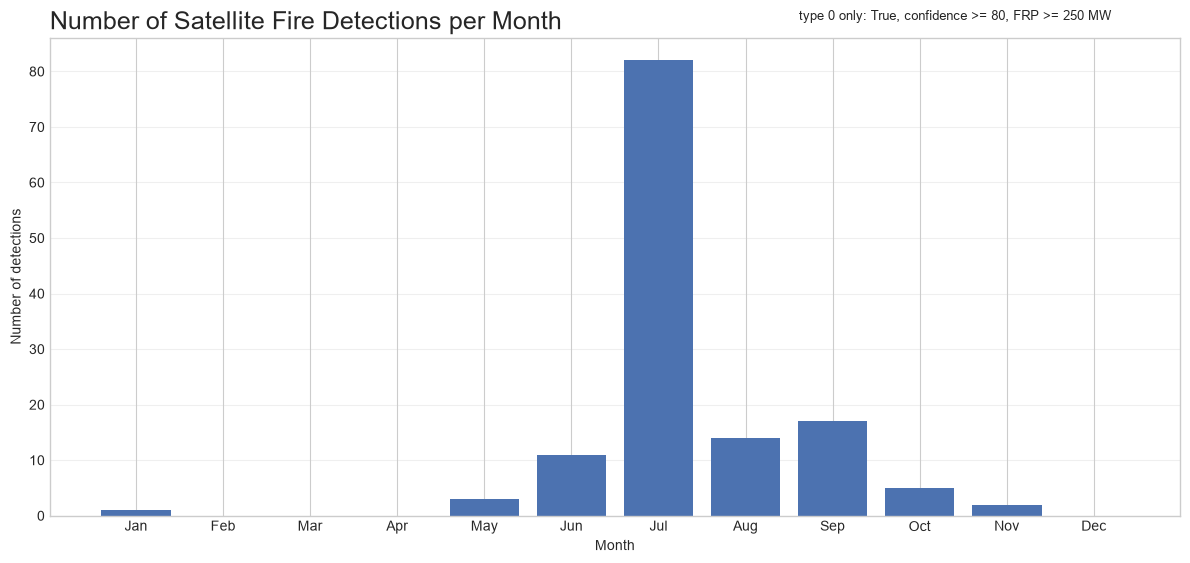

In [16]:
monthly_counts = df.groupby("month").size().reindex(range(1, 13), fill_value=0)

plt.figure(figsize=(12, 6))
plt.bar(monthly_counts.index, monthly_counts.values)
plt.title("Number of Satellite Fire Detections per Month", loc="left", fontsize=18)
plt.suptitle(FILTER_LABEL, x=0.8, y=0.93, fontsize=9)
plt.xlabel("Month")
plt.ylabel("Number of detections")
plt.xticks(range(1, 13), MONTH_LABELS)
plt.grid(axis="y", alpha=0.3)
save_plot("01_monthly_detections.png")

**What it shows:** how many hot-spot detections occurred each month. Detections follow the seasons in California with a rise through the dry summer months and peaks in the late-summer / autumn fire season. There are also far fewer detections in winter. 

### Plot 2: Monthly mean and median FRP

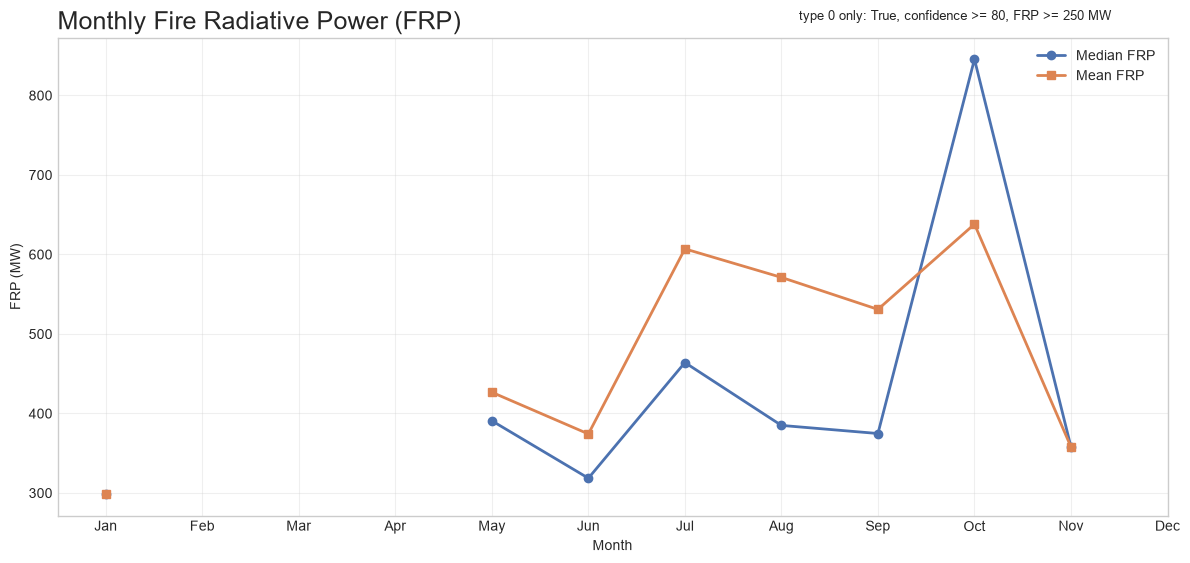

In [17]:
monthly_frp = (df.groupby("month")["frp"].agg(mean="mean", median="median").reindex(range(1, 13)))

plt.figure(figsize=(12, 6))
plt.plot(monthly_frp.index, monthly_frp["median"], marker="o", linewidth=2, label="Median FRP")
plt.plot(monthly_frp.index, monthly_frp["mean"], marker="s", linewidth=2, label="Mean FRP")
plt.title("Monthly Fire Radiative Power (FRP)", loc="left", fontsize=18)
plt.suptitle(FILTER_LABEL, x=0.8, y=0.93, fontsize=9)
plt.xlabel("Month")
plt.ylabel("FRP (MW)")
plt.xticks(range(1, 13), MONTH_LABELS)
plt.legend()
plt.grid(True, alpha=0.3)
save_plot("02_monthly_frp.png")

**What it shows:** how intense the fires were each month. The mean mostly sits above the median because of a few very intense fires. When the mean spikes but the median doesn't, one or two huge fires are responsible.

### Plot 3: Distribution of FRP

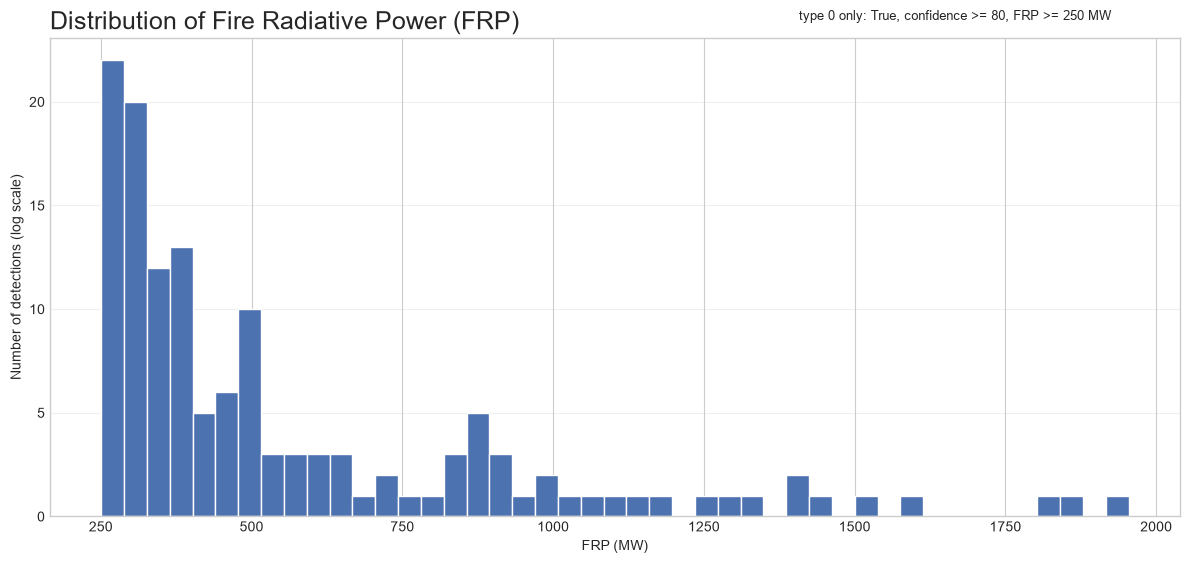

In [18]:
plt.figure(figsize=(12, 6))
plt.hist(df["frp"], bins=45, edgecolor="white")
#plt.yscale("log")   # log scale so the rare very intense fires are still visible
plt.title("Distribution of Fire Radiative Power (FRP)", loc="left", fontsize=18)
plt.suptitle(FILTER_LABEL, x=0.8, y=0.93, fontsize=9)
plt.xlabel("FRP (MW)")
plt.ylabel("Number of detections (log scale)")
plt.grid(axis="y", alpha=0.3)
save_plot("03_frp_distribution.png")

**What it shows:** the vast majority of detections are small (tens of MW) and only a handful are very large. Play around with the filters and log axis to see the small detections. 

### PLot 5: List and Locations of largest FRP 

In [19]:
top = (
    df.nlargest(40, "frp")[["acq_date", "acq_time", "daynight", "satellite",
                            "latitude", "longitude", "frp", "confidence", "COUNTY_NAME"]]
      .sort_values(["acq_date", "acq_time"])
      .reset_index(drop=True)
)
top

,acq_date,acq_time,daynight,satellite,latitude,longitude,frp,confidence,COUNTY_NAME
0,2010-06-12,1858,D,Terra,32.6797,-115.3543,872.9,100,Imperial
1,2010-07-13,2130,D,Aqua,33.3217,-117.3818,1303.2,100,San Diego
2,2010-07-13,2130,D,Aqua,33.3251,-117.3881,818.9,100,San Diego
3,2010-07-27,1826,D,Terra,35.8094,-118.4831,1578.7,100,Tulare
4,2010-07-27,1826,D,Terra,35.8072,-118.4887,1249.7,100,Tulare
5,2010-07-27,1826,D,Terra,35.8057,-118.4745,1166.3,100,Tulare
6,2010-07-27,1826,D,Terra,35.8027,-118.4167,730.2,100,Tulare
7,2010-07-27,2143,D,Aqua,35.8034,-118.3978,1954.3,100,Tulare
8,2010-07-27,2143,D,Aqua,35.8262,-118.4886,1850.8,100,Tulare
9,2010-07-27,2143,D,Aqua,35.8119,-118.4876,1423.9,100,Tulare


### Plot 6: FRP by day and night

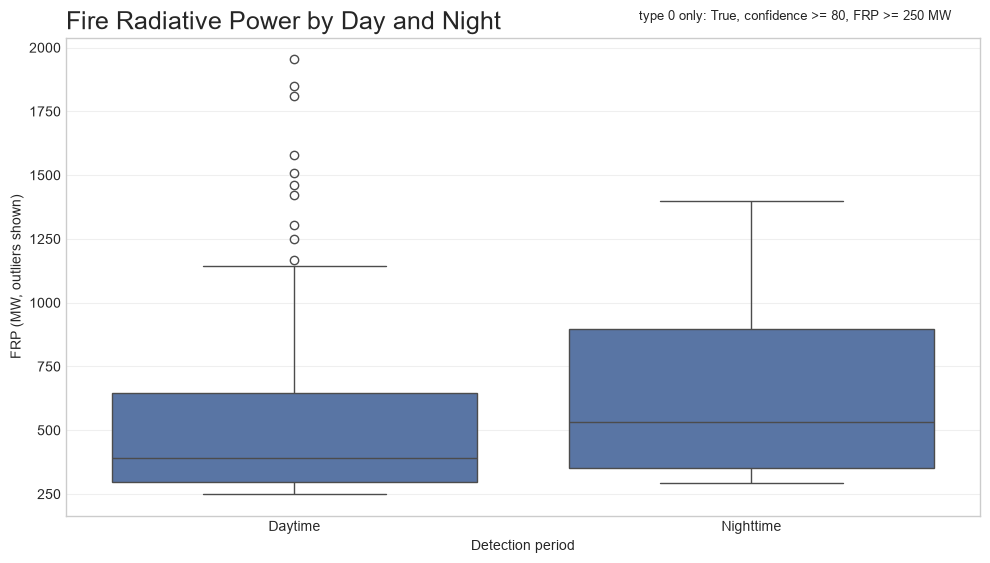

In [20]:
daynight = df[df["daynight"].isin(["D", "N"])].copy()
daynight["Detection period"] = daynight["daynight"].map({"D": "Daytime", "N": "Nighttime"})

plt.figure(figsize=(10, 6))
sns.boxplot(data=daynight, x="Detection period", y="frp", showfliers=True)
plt.title("Fire Radiative Power by Day and Night",  loc="left", fontsize=18)
plt.suptitle(FILTER_LABEL, x=0.8, y=0.93, fontsize=9)
plt.xlabel("Detection period")
plt.ylabel("FRP (MW, outliers shown)")
plt.grid(axis="y", alpha=0.3)
save_plot("04_frp_day_night.png")

### Plot 7: Geographical distribution of detections

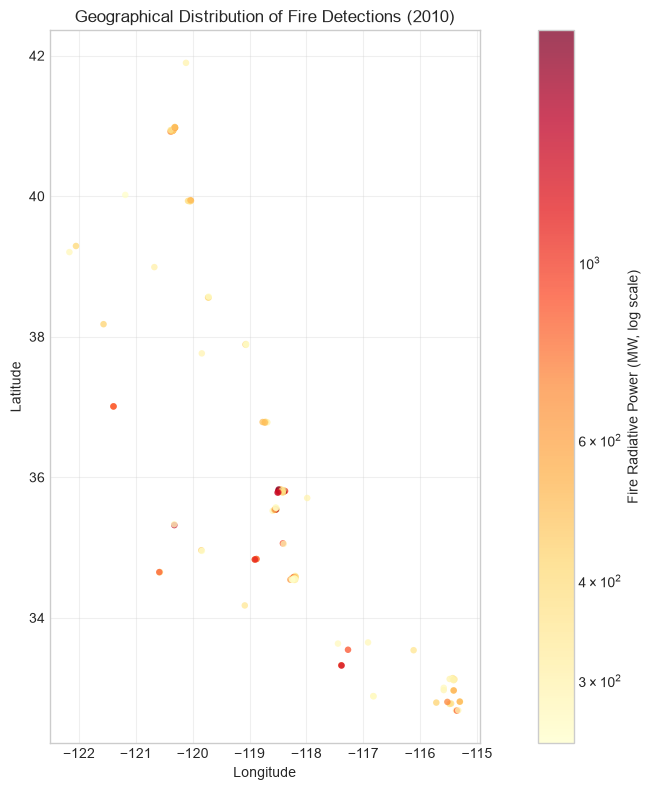

In [21]:
fig, ax = plt.subplots(figsize=(12, 8))
scatter = ax.scatter(df["longitude"], df["latitude"], c=df["frp"], cmap="YlOrRd",
                     s=22, alpha=0.75, edgecolors="none",
                     norm=mcolors.LogNorm(vmin=max(df["frp"].min(), 1), vmax=df["frp"].max()))
fig.colorbar(scatter, ax=ax).set_label("Fire Radiative Power (MW, log scale)")
ax.set_title("Geographical Distribution of Fire Detections (2010)")
#fig.suptitle(FILTER_LABEL, y=0.93, fontsize=9)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(df["latitude"].mean())))   # keep California's shape
ax.grid(True, alpha=0.3)
save_plot("06_geographical_scatter.png")

## 4. Interactive map

### How this map works

- **Background**: satellite imagery plus a transparent layer of place names. Use the layer control to switch them.
- **One circle per detection** with FRP >= `MAP_MIN_FRP` (100 MW in example).
- **Bigger, redder and more opaque circle = higher FRP.**
- **Hover** over a circle to see its FRP, date and county.
- The legend shows the FRP colour scale.

In [22]:
# 1. Select the detections to plot
map_df = df.copy()

# 2. Create the base map, centred on the data (tiles=None so we can add our own layers)
m = folium.Map(location=[map_df["latitude"].mean(), map_df["longitude"].mean()],zoom_start=6, tiles=None)

folium.TileLayer(xyz.Esri.WorldImagery, name="Satellite imagery").add_to(m)
folium.TileLayer(xyz.OpenStreetMap.Mapnik, name="OpenStreetMap").add_to(m)
folium.TileLayer(xyz.Stadia.StamenTonerLabels, name="Place names", overlay=True).add_to(m)

# 3. Colour scale: yellow (lowest FRP) to orange to red (highest FRP)
min_frp = float(map_df["frp"].min())
max_frp = float(map_df["frp"].max())
#if max_frp <= min_frp:
 #   max_frp = min_frp + 1
cmap = plt.get_cmap("YlOrRd")
norm = mcolors.Normalize(vmin=min_frp, vmax=max_frp)

# 4. Add one circle per detection
for index, row in map_df.iterrows():
    frp_value = float(row["frp"])
    scaled = (frp_value - min_frp) / (max_frp - min_frp)       # 0 (weakest) to 1 (strongest)

    radius = 2 + scaled * 13                                   # bigger for higher FRP
    opacity = 0.4 + scaled * 0.5                               # less transparent for higher FRP
    colour = mcolors.to_hex(cmap(norm(frp_value)))

    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=radius, color=colour, weight=1,
        fill=True, fill_color=colour, fill_opacity=opacity,
        tooltip=(f"FRP: {frp_value:.1f} MW | Date: {row['acq_date']:%Y-%m-%d} | "
                 f"County: {row['COUNTY_NAME']}"),
    ).add_to(m)

# 5. Legend, layer switcher and zoom to fit all points
legend = cm.LinearColormap(colors=["yellow", "orange", "red"], vmin=min_frp, vmax=max_frp)
legend.width = 600
#legend.caption = f"Fire Radiative Power (MW), detections >= {MIN_FRP}"
legend.caption = f"Fire Radiative Power (MW), detections >= {MIN_FRP} | {FILTER_LABEL}"
legend.add_to(m)
folium.LayerControl().add_to(m)
m.fit_bounds([[map_df["latitude"].min(), map_df["longitude"].min()], # frame the data 
              [map_df["latitude"].max(), map_df["longitude"].max()]])

# 6. Save as a standalone HTML file and show it in the notebook
map_path = OUTPUT_DIR / "07_interactive_wildfire_map.html"
m.save(str(map_path))
print(f"{len(map_df):,} detections plotted. Map saved to: {map_path.resolve()}")
display(m)

135 detections plotted. Map saved to: C:\Users\Phoeb\OneDrive\Desktop\Fourth Year\Data Intensive\GitHub\Sample data\wildfire_2010_outputs\07_interactive_wildfire_map.html


# References for the map plot

- https://python-visualization.github.io/folium/latest/reference.html
- https://xyzservices.readthedocs.io/en/latest/api.html#xyzservices.TileProvider
- https://xyzservices.readthedocs.io/en/stable/
- https://leaflet-extras.github.io/leaflet-providers/preview/
- https://python-visualization.github.io/folium/latest/user_guide/ui_elements/layer_control.html

Note: 
**Folium:** Python library that builds interactive web maps. It produces a map with pan and zoom features available.

The map comes from **tile providers:** services such as OpenStreetMap or Esri that cut the world map into small square pictures (tiles) and serve them on request. A map shows only the tiles it needs for the current view and zoom level.

**xyzservices** is a small Python package that keeps a catalogue of these providers.

## Summary

- 2,951 MODIS detections over California in 2010; 2,776 are presumed vegetation fires.
- FRP is highly skewed: most detections are small, a few are enormous.
- There is no official definition of a "wildfire", therefore the choice of filters (`type`, `confidence`, `FRP`) is part of the analysis.

In [23]:
#print(xyz.Esri.WorldImagery.build_url())
#print(xyz.Esri.WorldImagery.html_attribution)

In [24]:
# Note - changing min confidence from 50 to 80 shows little difference in the plots

In [25]:
# Note - Still seems to be burning crop fires (corners of fields) for FRP greater than 250MW. Highest found is around 500MW